# Example: Q-Learning in the Lava Grid World
You have a [roomba](https://www.irobot.com) that has finished cleaning the kitchen floor and needs to return to its charging station. However, between the kitchen floor and the charging station there are lava pits, which destroy the roomba.

In this example, we use Q-learning to guide the roomba to its charging station while it avoids the lava pits. The roomba is not told where either one is.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * __Run tabular Q-learning:__ Q-learning keeps a table of action values and updates one entry after each move, using only the reward and the next square that the world returns. We'll walk through the pseudocode and the course package function that runs the algorithm.
> * __Learn a path through the lava grid world:__ The roomba starts with a table of zeros and learns from many episodes of trial and error. We'll train it and draw the path its learned policy takes to the charging station.
> * __Compare the learned policy with the optimal one computed by value iteration:__ Value iteration computes the optimal policy because it knows the rewards and the transition probabilities. We'll follow both policies from the same starting square and compare their paths and their scores.

Let's get started!
___

## Setup, Data, and Prerequisites

First, we load the local [`Include.jl`](Include.jl) setup file and its required packages.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates [`Include.jl`](Include.jl) in the notebook's global scope. The setup file activates the course project, defines local paths, and loads the course package, this example's code in the [src](src) folder, and the packages used here.

Let's set up our code environment:

In [1]:
# Load packages and paths from this notebook's local setup file -
include(joinpath(@__DIR__, "Include.jl"));

# Choose one theme; after changing it, rerun this cell and the plotting cells -
theme(:default)   # light background
# theme(:dark)   # dark background

In addition to standard Julia libraries, we'll use [the `VLDataScienceMachineLearningPackage.jl` package](https://github.com/varnerlab/VLDataScienceMachineLearningPackage.jl). Check out [the documentation](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/) for more information on the functions, types, and data used in this material.

The grid world functions are in [src/GridWorld.jl](src/GridWorld.jl).
___

## Task 1: Build the Lava Grid World
In this task, we build the lava grid world and a function that lets the roomba try a move and see what happens.

We use the same lava grid world as before: a 20 by 20 grid with a charging station and five lava pits. We represent it with [the `MyRectangularGridWorldModel` type](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/mdp/#VLDataScienceMachineLearningPackage.MyRectangularGridWorldModel), which maps $(x,y)$ coordinates onto discrete states.

> __Grid World Structure:__ The model holds:
> * a rectangular grid, with one state per square
> * a reward for reaching the charging station, and a penalty for a lava pit
> * a small cost for every ordinary move, which rewards a short path
> * absorbing states, the charging station and the lava pits: once the roomba enters one, the episode ends

Let's set the grid dimensions, the number of actions, and the discount factor $\gamma$ that weighs future rewards against immediate ones:

In [2]:
number_of_rows = 20; # number of rows in the grid world
number_of_cols = 20; # number of cols in the grid world
nactions = 4; # number of actions: left, right, down, up
γ = 0.95; # discount factor
nstates = (number_of_rows*number_of_cols); # number of states, one for each square
𝒮 = range(1,stop=nstates,step=1) |> collect; # states
𝒜 = range(1,stop=nactions,step=1) |> collect; # actions

Next we describe what each square is worth, in the `rewards::Dict{Tuple{Int,Int}, Float64}` dictionary, which maps an $(x,y)$ coordinate to a reward, and the `absorbing_state_set::Set{Tuple{Int,Int}}` set, which collects the squares that end the episode. Only the squares that differ from an ordinary move appear here:

In [3]:
# setup the rewards - only the world knows the rewards, not the agent. The agent must learn them by moving around in the world.
lava_reward = -1000.0;
charging_reward = 100.0;

rewards = Dict{Tuple{Int,Int}, Float64}()
rewards[(1,2)] = lava_reward # lava in the (1,2) square
rewards[(2,2)] = lava_reward # lava in the (2,2) square
rewards[(2,3)] = lava_reward # lava in the (2,3) square
rewards[(4,5)] = lava_reward # lava in the (4,5) square
rewards[(19,20)] = lava_reward # lava in the (19,20) square
rewards[(4,3)] = charging_reward   # charging station square

# setup set of absorbing states -
absorbing_state_set = Set{Tuple{Int,Int}}()
for (k,v) ∈ rewards
    push!(absorbing_state_set, k);
end

Now we build the world itself. [The `build(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/factory/) takes the dimensions and the rewards and returns a `world::MyRectangularGridWorldModel` instance holding the coordinate system and the moves available from each square:

In [4]:
world = build(MyRectangularGridWorldModel,
    (nrows = number_of_rows, ncols = number_of_cols, rewards = rewards)); # Always: type of thing, data to build that thing

### The world the roomba cannot see
Next, we build the reward matrix $R(s,a)$ and the transition array $T(s^{\prime}\,|\,s,a)$ with the same rules we used for value iteration. However, the roomba does not see these: it only sees the reward and the next square after it makes a move.

The reward is an `R::Array{Float64,2}` matrix of size $|\mathcal{S}|\times|\mathcal{A}|$, where $R[s,a]$ is what the roomba collects for taking action $a$ in state $s$. For each state and action, we work out where the roomba lands and assign the matching reward. An absorbing state earns nothing further, because the episode has already ended:

In [5]:
R = let

    # initialize -
    R = zeros(nstates, nactions);
    step_reward = -1.0; # the cost of an ordinary move
    off_grid_reward = -50000.0; # a large penalty for trying to leave the grid

    # main loop: compute where each action takes the roomba, and assign the reward -
    for s ∈ 𝒮
        for a ∈ 𝒜

            Δ = world.moves[a]; # the move for this action, e.g., up = (0,1)
            current_position = world.coordinates[s]; # where we are now
            new_position = current_position .+ Δ; # where action a takes us

            if (in(current_position, absorbing_state_set) == true)
                R[s,a] = 0.0; # the episode has ended: we earn nothing more
            elseif (haskey(world.states, new_position) == true)
                if (haskey(rewards, new_position) == true)
                    R[s,a] = rewards[new_position]; # the charging station or a lava pit
                else
                    R[s,a] = step_reward; # an ordinary move
                end
            else
                R[s,a] = off_grid_reward; # off the grid: a large penalty
            end
        end
    end

    R; # return R
end;

The transition function is a `T::Array{Float64,3}` array of size $|\mathcal{S}|\times|\mathcal{S}|\times|\mathcal{A}|$, where $T[s,s^{\prime},a]$ is the probability of reaching $s^{\prime}$ from $s$ under action $a$. Our roomba always goes where it intends:
* A legal move from a state that is not absorbing gives $T[s,s^{\prime},a]=1$ for the square the move reaches.
* A move off the grid, or any move from an absorbing state, gives $T[s,s,a]=1$: the roomba stays put.

In [6]:
T = let

    # initialize -
    T = zeros(nstates, nstates, nactions);

    # main loop: each action moves the roomba to exactly one square -
    for a ∈ 𝒜

        Δ = world.moves[a]; # the move for this action

        for s ∈ 𝒮
            current_position = world.coordinates[s]; # where we are now
            new_position = current_position .+ Δ; # where action a takes us

            if (haskey(world.states, new_position) == true &&
                    in(current_position, absorbing_state_set) == false)
                s′ = world.states[new_position];
                T[s, s′, a] = 1.0; # a legal move: we land on the new square
            else
                T[s, s, a] = 1.0; # off the grid, or the episode has ended: we stay put
            end
        end
    end

    T; # return T
end;

Finally, we package the states, the actions, $T$, $R$, and $\gamma$ into an instance of [the `MyMDPProblemModel` type](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/mdp/#VLDataScienceMachineLearningPackage.MyMDPProblemModel). [The `build(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/factory/) constructs the `m::MyMDPProblemModel` instance:

In [7]:
m = build(MyMDPProblemModel, (
    𝒮 = 𝒮, # states
    𝒜 = 𝒜, # actions
    T = T, # transition model
    R = R, # reward model
    γ = γ # discount factor
));

Value iteration reads $R$ and $T$ directly, but the Q-learning agent never does. It learns through [the `lavaworld(...)` function](src/GridWorld.jl) instead.

Given a state $s$ and an action $a$, the function returns the next state $s^{\prime}$ and the reward $r$, as if the roomba had made the move. It draws the next state at random from $T(s^{\prime}\,|\,s,a)$, using the random number generator it takes as its last argument.

Let's try one move: from the square $(20,20)$, move left, which is action `1`:

In [8]:
let
    s = world.states[(20,20)]; # the state of the square (20,20)
    (s′, r) = lavaworld(m, s, 1, Xoshiro(1)); # move left; Xoshiro(1) is a random number generator with seed 1
    println("the roomba moved from ", world.coordinates[s], " to ", world.coordinates[s′], " and collected ", r)
end

the roomba moved from (

20, 20) to (19, 20) and collected -1000.0


The square to the left of $(20,20)$ is the lava pit at $(19,20)$. This one move costs the roomba 1000 and would end its episode. The roomba learns where the lava pits are only by entering them.

Finally, the agent needs to know which states end an episode. We collect their state numbers in the `absorbing_states::Set{Int64}` set:

In [9]:
absorbing_states = Set{Int64}(); # the states that end an episode
for coordinate ∈ absorbing_state_set
    push!(absorbing_states, world.states[coordinate]);
end

___

## Task 2: Train the Roomba with Q-Learning
In this task, we walk through the Q-learning algorithm and train the roomba.

Q-learning estimates the action-value function $Q(s,a)$ from the moves the roomba makes. After each move, it updates one entry of the table:

$$
\begin{equation*}
Q(s,a)\gets Q(s,a)+\alpha\left(r+\gamma\max_{a^{\prime}\in\mathcal{A}}Q(s^{\prime},a^{\prime})-Q(s,a)\right)
\end{equation*}
$$

where $0<\alpha\leq 1$ is the learning rate and $\gamma$ is the discount factor. The term $r+\gamma\max_{a^{\prime}}Q(s^{\prime},a^{\prime})$ is the temporal difference target, and its difference from $Q(s,a)$ is the temporal difference error.

__Initialize__: Given the state space $\mathcal{S}$, the action space $\mathcal{A}$, the absorbing states, a discount factor $0\leq\gamma<1$, a learning rate $0<\alpha\leq 1$, an exploration probability $0\leq\epsilon\leq 1$, a number of episodes $N\geq 1$, and a maximum number of steps per episode $d\geq 1$, set $Q(s,a)\gets 0$ for all $s\in\mathcal{S}$ and $a\in\mathcal{A}$.

For $i = 1$ to $N$ __do__:
1. Choose a starting state $s$ that is not absorbing, uniformly at random, and set the step counter $t\gets 0$.
2. While $s$ is not absorbing and $t<d$ __do__:
    - Choose the action $a$: roll a random number $p\in[0,1]$.
        - If $p\leq\epsilon$ __then__ choose $a\in\mathcal{A}$ uniformly at random (exploration).
        - Otherwise, choose the greedy action $a\gets\arg\max_{a^{\prime}\in\mathcal{A}}Q(s,a^{\prime})$ (exploitation).
    - Take action $a$, and observe the reward $r$ and the next state $s^{\prime}$ from the world.
    - Update the action value with the temporal difference error:
      $$Q(s,a)\gets Q(s,a)+\alpha\left(r+\gamma\max_{a^{\prime}\in\mathcal{A}}Q(s^{\prime},a^{\prime})-Q(s,a)\right)$$
    - Update the state $s\gets s^{\prime}$ and the step counter $t\gets t+1$.

__Extract Policy__: For each state $s\in\mathcal{S}$, compute $\pi(s)\gets\arg\max_{a\in\mathcal{A}}Q(s,a)$.

We store the agent in a `MyQLearningAgentModel` instance from the course package. [The `build(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/factory/) takes the states, the actions, the learning rate $\alpha$, the discount factor $\gamma$, and the starting table $Q$, all zeros.

Let's set the training constants and build the agent:

In [10]:
α = 0.5; # learning rate (you can change this)
ϵ = 0.1; # exploration probability (you can change this)
number_of_episodes = 2000; # number of episodes N (you can change this)
maxsteps = 500; # maximum number of steps per episode d
agent = build(MyQLearningAgentModel, (
    states = 𝒮, # the states
    actions = 𝒜, # the actions
    α = α, # the learning rate
    γ = γ, # the discount factor
    Q = zeros(nstates, nactions), # the starting table: all zeros
));

### Train the roomba
[The `solve(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/qlearning/) of the course package takes the agent and the MDP `m`, and carries out the pseudocode above. It returns a `NamedTuple` holding the learned table `Q` and the counts `visits`, where `visits[s,a]` is the number of times the roomba took action `a` in state `s`.

By default, every update uses the agent's learning rate $\alpha$. The keyword `learningrate = :visits` uses $\alpha=1/n$ on the $n$-th update of a pair instead. Every random draw comes from a generator seeded with `seed`. A rerun with the same seed gives the same result.

In [11]:
result = solve(agent, m; worldmodel = lavaworld, absorbing = absorbing_states,
    episodes = number_of_episodes, maxsteps = maxsteps, ϵ = ϵ, seed = 5800); # train the roomba
println("moves made during training: ", sum(result.visits))

moves made during training: 53582

___

## Task 3: Compare with Value Iteration
In this task, we compare the learned policy with the optimal policy. Value iteration knows $R$ and $T$, which lets it compute the optimal values directly.

[The `solve(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/mdp/#VLDataScienceMachineLearningPackage.solve-Tuple{MyValueIterationModel,%20MyMDPProblemModel}) runs value iteration, [the `Q(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/mdp/#VLDataScienceMachineLearningPackage.Q-Tuple{MyMDPProblemModel,%20Vector{Float64}}) turns the optimal values into the optimal action values $Q^{*}(s,a)$, and [the `policy(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/mdp/#VLDataScienceMachineLearningPackage.policy-Tuple{Matrix{Float64}}) reads the best action from each row of a table.

Let's compute the optimal policy and read the learned one:

In [12]:
solution = solve(MyValueIterationModel(1000), m); # value iteration, at most 1000 sweeps
Qstar = Q(m, solution.U); # the optimal action values Q*(s,a), one row per state
π_star = policy(Qstar); # the optimal policy
π_q = policy(result.Q); # the learned policy

### Follow both policies
Now let's follow the learned policy and the optimal policy from the same starting square. Specify a `startstate::Tuple{Int,Int}` as an $(x, y)$ coordinate tuple:

In [13]:
startstate = (20,20); # where to start the path simulation (you can change this)

[The `follow_policy(...)` function](src/GridWorld.jl) starts at a square and applies the policy one move at a time, until the roomba enters an absorbing state, tries to leave the grid, or returns to a square it has already visited, which means it would walk in a loop forever:

In [14]:
# walk each policy from the start square -
(path, outcome) = follow_policy(π_q, startstate, world, rewards, absorbing_state_set;
    charging_reward = charging_reward);
(path_star, outcome_star) = follow_policy(π_star, startstate, world, rewards, absorbing_state_set;
    charging_reward = charging_reward);

println("learned policy: the roomba ", outcome, " after ", length(path) - 1, " moves")
println("optimal policy: the roomba ", outcome_star, " after ", length(path_star) - 1, " moves")

learned policy: the roomba reached the charging station after 33 moves
optimal policy: the roomba reached the charging station after 33 moves


Let's draw both paths on one figure. [The `draw_paths(...)` function](src/GridWorld.jl) marks the charging station in green and the lava pits in red. A gray arrow in each of the other squares shows the move the learned policy chooses there.

The optimal path is the orange band, and the learned path is the blue line, both starting at the blue dot:

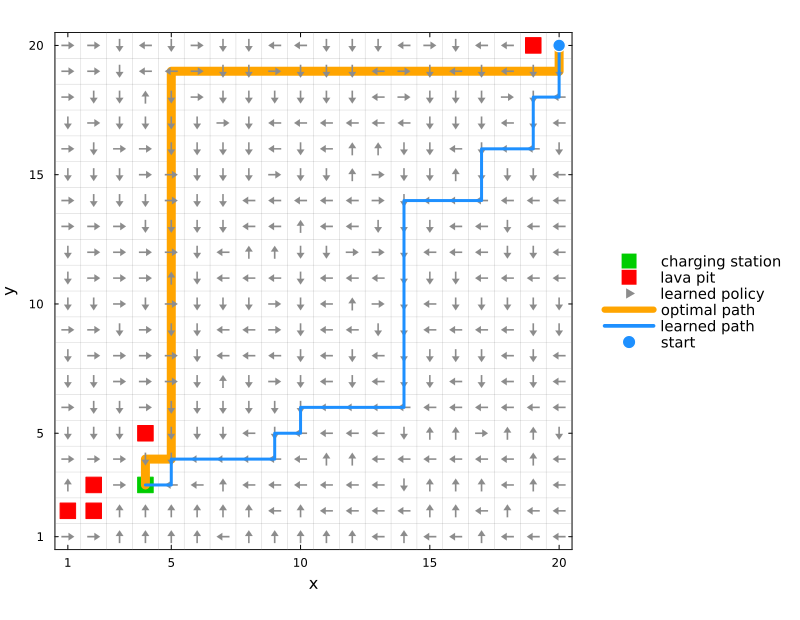

In [15]:
# draw the grid, the learned policy, the optimal path, and the learned path -
draw_paths(path, path_star, π_q, world, rewards, absorbing_state_set;
    charging_reward = charging_reward, lava_reward = lava_reward,
    number_of_rows = number_of_rows, number_of_cols = number_of_cols)

Finally, let's score each policy. Starting at `startstate`, the roomba follows the policy until it enters an absorbing state or makes `maxsteps` moves. The score is the discounted sum of the rewards it collects, $\sum_{t=1}^{n}\gamma^{t-1}r_{t}$, where $r_{t}$ is the reward of move $t$ and $n$ is the number of moves:

In [16]:
let

    # initialize -
    s_start = world.states[startstate]; # the state of the start square
    policies = [π_q, π_star]; # the two policies we score: learned first, then optimal
    rng = Xoshiro(1); # lavaworld needs a random number generator; every move here is certain

    # main loop: score each policy -
    for i ∈ 1:2
        π = policies[i]; # the policy we score
        score = 0.0; # the discounted sum of the rewards so far
        s = s_start; # the roomba starts here
        for t ∈ 1:maxsteps
            if (in(s, absorbing_states) == true)
                break; # the episode has ended
            end
            a = π[s]; # the move the policy chooses in state s
            (s′, r) = lavaworld(m, s, a, rng); # make the move: the next state and the reward
            score = score + γ^(t-1)*r; # add the reward of move t, discounted
            s = s′;
        end

        # print the score; for the learned policy, also print its estimate for the start square -
        if (i == 1)
            estimate = maximum(result.Q[s_start, :]); # the largest of the four learned numbers for the start square
            println("score of the learned policy from ", startstate, ": ", round(score, digits = 2),
                " (the learned estimate: ", round(estimate, digits = 2), ")")
        else
            println("score of the optimal policy from ", startstate, ": ", round(score, digits = 2))
        end
    end
end

score of the learned policy from (20, 20): 3.25 (the learned estimate: -2.35)
score of the optimal policy from (20, 20): 3.25


__Why do the score and the estimate differ?__ The estimate is what the learned table predicts the roomba will earn from the start square. That prediction is still too low.

To choose a move, the policy only compares the four numbers the table stores for a square, one per move, and takes the largest. The numbers are too low, but the largest one already points to a best move in every square of the path. That is why both policies earn the same score.

___

## Summary
In this example, we trained a roomba with Q-learning to navigate the lava grid world from its own moves, and compared the policy it learned with the optimal policy from value iteration.

> __Key Takeaways:__
>
> * __Q-learning needs only the moves the roomba makes:__ Our roomba learned from the next square and the reward of each move, which a simulator returned, without ever reading the rewards or the transition probabilities. One update per move, toward the temporal difference target, was enough to learn a shortest path to the charging station.
>
> * __A low estimate can still pick a best move:__ After 2000 episodes, the learned policy earned the same score from the start square as the optimal policy, although the learned estimate for that square was still too low. The policy only needs the largest number in each square of the learned table to be on a best move.
>
> * __Learning from moves takes many moves:__ Q-learning made more than 50,000 moves of trial and error to learn its path to the charging station. Value iteration computed the optimal policy without making any moves, because it could read the rewards and the transition probabilities.

We can now change the number of episodes, the exploration probability, or the learning rate and see how the learned policy responds.

___